# Visualize the migrated final objects (new vocabulary)

Reads the **staged migrated** `final_{sp}_migrated.h5ad` objects (the new `cell_type`/`cell_subtype`
vocabulary), and renders UMAP + composition + a marker sanity dotplot, using `uns["display_names"]`
for pretty labels. Any scanpy env works (`rsc_uv` fine). Set `SPECIES` and re-run.

**Which objects:** the staged migrated set (new vocab), NOT the live Jul-29 objects (old vocab).
If you've already promoted, point PATH at the live `final_{sp}.h5ad` instead.

## Load

In [1]:
%matplotlib inline
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt, scanpy as sc

SPECIES = "human"     # "human" | "mouse"
RUN = "xmens_annotation_v1_20260810"
PATH = f"data/interim/migrated/{RUN}/final_{SPECIES}_migrated.h5ad"
# after promotion, instead: PATH = f"data/interim/final_{SPECIES}.h5ad"

a = ad.read_h5ad(PATH)
disp = a.uns.get("display_names", {})
dt = disp.get("cell_type", {}) if isinstance(disp, dict) else {}
ds = disp.get("cell_subtype", {}) if isinstance(disp, dict) else {}
print(a.shape)
print("cell_type:", sorted(a.obs["cell_type"].astype(str).unique()))
print("has display_names:", bool(dt))
# map to display labels for plotting (fall back to raw if missing)
a.obs["ct_disp"] = a.obs["cell_type"].astype(str).map(lambda x: dt.get(x, x))
a.obs["cst_disp"] = a.obs["cell_subtype"].astype(str).map(lambda x: ds.get(x, x) if x else "(none)")

(66830, 36601)
cell_type: ['decidual_cell', 'endometrial_fibroblast', 'endothelial_cell', 'epithelial_cell', 'immune_cell', 'perivascular_cell', 'smooth_muscle_cell']
has display_names: True


## 1. Coarse cell_type on UMAP

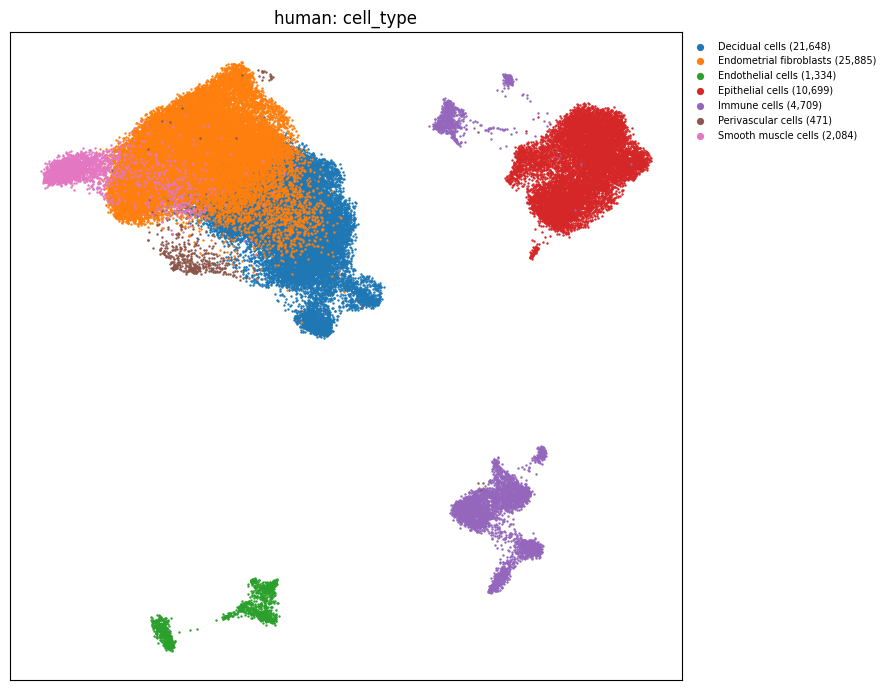

In [3]:
umap_key = "X_umap_scVI" if "X_umap_scVI" in a.obsm else ("X_umap_scVI" if "X_umap_migrated" in a.obsm else None)
assert umap_key, f"no UMAP in obsm: {list(a.obsm)}"
U = np.asarray(a.obsm[umap_key])
cats = a.obs["ct_disp"].astype("category")
cmap = plt.get_cmap("tab10" if cats.cat.categories.size<=10 else "tab20")
fig, ax = plt.subplots(figsize=(9,7))
for i,c in enumerate(cats.cat.categories):
    m = (a.obs["ct_disp"]==c).values
    ax.scatter(U[m,0], U[m,1], s=3, color=cmap(i%cmap.N), label=f"{c} ({int(m.sum()):,})", linewidths=0)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{SPECIES}: cell_type")
ax.legend(markerscale=3, fontsize=7, frameon=False, bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

## 2. Fine cell_subtype on UMAP (cells with a subtype)

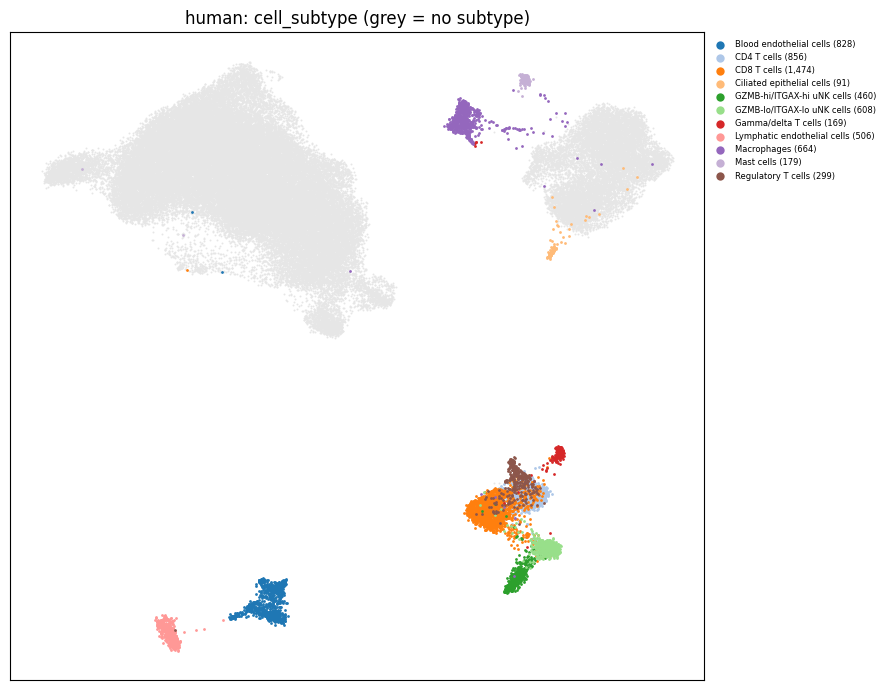

In [4]:
has_sub = (a.obs["cell_subtype"].astype(str).str.len()>0).values
sub = a.obs.loc[has_sub, "cst_disp"].astype("category")
cmapS = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(9,7))
ax.scatter(U[~has_sub,0], U[~has_sub,1], s=2, color="0.9", linewidths=0)  # no-subtype greyed
for i,c in enumerate(sorted(sub.cat.categories)):
    m = has_sub & (a.obs["cst_disp"]==c).values
    ax.scatter(U[m,0], U[m,1], s=4, color=cmapS(i%cmapS.N), label=f"{c} ({int(m.sum()):,})", linewidths=0)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{SPECIES}: cell_subtype (grey = no subtype)")
ax.legend(markerscale=3, fontsize=6, frameon=False, ncol=1, bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

## 3. Composition

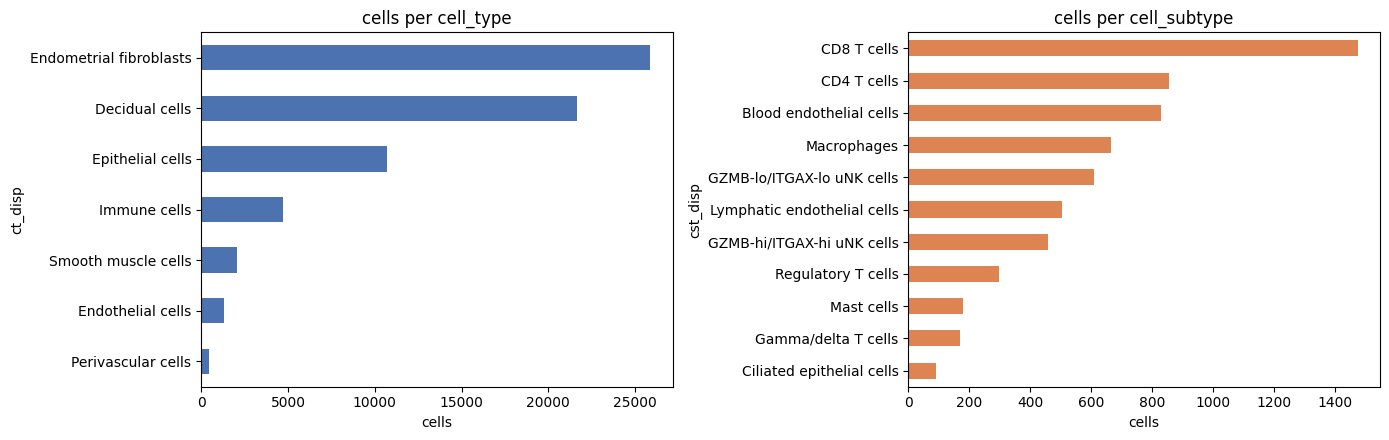

ct_disp                  cst_disp                   
Decidual cells           (none)                         21648
Endometrial fibroblasts  (none)                         25885
Endothelial cells        Blood endothelial cells          828
                         Lymphatic endothelial cells      506
Epithelial cells         (none)                         10608
                         Ciliated epithelial cells         91
Immune cells             CD8 T cells                     1474
                         CD4 T cells                      856
                         Macrophages                      664
                         GZMB-lo/ITGAX-lo uNK cells       608
                         GZMB-hi/ITGAX-hi uNK cells       460
                         Regulatory T cells               299
                         Mast cells                       179
                         Gamma/delta T cells              169
Perivascular cells       (none)                           471
Smooth muscle cel

In [5]:
fig, ax = plt.subplots(1,2, figsize=(14,4.5))
a.obs["ct_disp"].value_counts().sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("cells per cell_type"); ax[0].set_xlabel("cells")
sc_counts = a.obs.loc[has_sub, "cst_disp"].value_counts().sort_values()
sc_counts.plot.barh(ax=ax[1], color="#DD8452")
ax[1].set_title("cells per cell_subtype"); ax[1].set_xlabel("cells")
plt.tight_layout(); plt.show()
print(a.obs.groupby("ct_disp")["cst_disp"].value_counts())

## 4. Marker sanity dotplot (coarse)
A quick "do the labels make sense" check — canonical markers per coarse type. Adjust the gene list to
your species' symbol casing (human UPPER, mouse Title). Uses `.X` (log-normalized) for the dotplot.

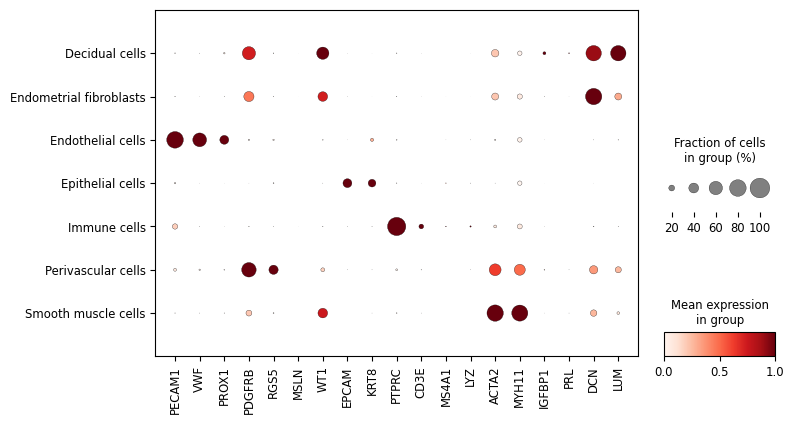

In [6]:
# canonical coarse markers — EDIT casing per species (human shown; for mouse use Title case)
MARKERS = {
 "human": ["PECAM1","VWF","PROX1","PDGFRB","RGS5","MSLN","WT1","EPCAM","KRT8",
           "PTPRC","CD3E","MS4A1","LYZ","ACTA2","MYH11","IGFBP1","PRL","DCN","LUM"],
 "mouse": ["Pecam1","Vwf","Prox1","Pdgfrb","Rgs5","Msln","Wt1","Epcam","Krt8",
           "Ptprc","Cd3e","Ms4a1","Lyz2","Acta2","Myh11","Igfbp1","Prl","Dcn","Lum"],
}[SPECIES]
present = [g for g in MARKERS if g in a.var_names]
missing = [g for g in MARKERS if g not in a.var_names]
if missing: print("absent from var_names (skipped):", missing)
sc.pl.dotplot(a, var_names=present, groupby="ct_disp", standard_scale="var",
              figsize=(max(8,0.4*len(present)), 0.5*a.obs["ct_disp"].nunique()+1))

## 5. (optional) Spatial — coarse type on tissue, per sample
Only if `obsm['spatial']` exists. Facets by sample if a sample column is present.

In [ ]:
if "spatial" in a.obsm:
    XY = np.asarray(a.obsm["spatial"])
    scol = next((c for c in ["sample","sample_id","library","batch"] if c in a.obs), None)
    samples = a.obs[scol].astype(str).unique() if scol else ["(all)"]
    samples = list(samples)[:6]
    fig, ax = plt.subplots(1, len(samples), figsize=(5*len(samples), 5), squeeze=False)
    cats = a.obs["ct_disp"].astype("category").cat.categories
    cmap = plt.get_cmap("tab10" if len(cats)<=10 else "tab20")
    col = {c:cmap(i%cmap.N) for i,c in enumerate(cats)}
    for j,s in enumerate(samples):
        m = (a.obs[scol].astype(str)==s).values if scol else np.ones(a.n_obs,bool)
        m &= np.isfinite(XY[:,0])
        for c in cats:
            mm = m & (a.obs["ct_disp"]==c).values
            if mm.sum(): ax[0,j].scatter(XY[mm,0], XY[mm,1], s=4, color=col[c], linewidths=0)
        ax[0,j].set_title(s, fontsize=8); ax[0,j].set_aspect("equal"); ax[0,j].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("no obsm['spatial'] on this object — skipping spatial panel")

In [9]:
print("STORED cell_type:", sorted(a.obs["cell_type"].astype(str).unique()))
print("STORED cell_subtype:", sorted(a.obs["cell_subtype"].astype(str).unique()))

STORED cell_type: ['decidual_cell', 'endometrial_fibroblast', 'endothelial_cell', 'epithelial_cell', 'immune_cell', 'perivascular_cell', 'smooth_muscle_cell']
STORED cell_subtype: ['', 'endothelial_blood', 'endothelial_lymph', 'epithelial_ciliated', 'macrophage', 'mast_cell', 't_cell_cd4', 't_cell_cd8', 't_cell_gamma_delta', 't_cell_regulatory', 'unk_cell_gzmb_high_itgax_high', 'unk_cell_gzmb_low_itgax_low']
